# T9 - EDA và giao thức đánh giá theo đợt cho bảy chiến dịch Seckin

Áp dụng giao thức mới cho Catalonia, Ghana_Nigeria, Iran_5, Spain, Thailand, Armenia và Bangladesh. P1 giữ quy tắc hài hòa thời gian. P2–P5 và P4b theo giao thức mới. P6 chỉ chạy khi có adapter T7.


| Tệp | Yêu cầu GVHD |
| --- | --- |
| `eda_overview.csv`, `p1_timestamps.csv` | Số liệu theo chiến dịch và nhãn để đối chiếu Bảng 1 khi viết data card; tỷ lệ giây 0 trước/sau P1 |
| `p2_daily_coverage.csv` | Bảng phủ theo ngày, c ∈ {1, 5, 10} |
| `p2_daily_relationship.csv` | Quan hệ số control với số IO theo ngày |
| `p2_account_day_activity.csv` | Bài/tài khoản/ngày theo nhãn |
| `p3_episodes.csv`, `p3_campaign_selection.csv` | Số đợt, đợt đạt, % hành động IO; bảng tiêu chí chọn chiến dịch cho cả ba ngưỡng control |
| `p4_checkpoints.csv`, `p4_checkpoint_counts.csv` | Lịch mốc; số mốc đạt và không đạt theo chiến dịch |
| `p5_baselines.csv`, `p4b_p5_summary.csv` | Ba baseline tầm thường, hai chiều; tổng hợp theo đợt với CI bootstrap |
| `p6_scores.csv`, `p6_deltas_vs_main.csv`, `p6_control_clusters.csv` | P6: điểm F1*, WP theo biến thể (hashtag, S1, cap K); thay đổi so với cấu hình chính, trung bình ± SD giữa seed; mô tả tổng hợp 10 cụm control hàng đầu. Chỉ có khi khai báo `t9_adapter` trong `configs/t7.json` |
| `p3_daily_coverage.png`, `p4_checkpoint_counts.png`, `run.json` | Hai hình cho báo cáo; cấu hình, git hash, thời gian chạy |

In [1]:
import json
import os
import re
import subprocess
import sys
from dataclasses import asdict
from datetime import datetime, timezone
from importlib import import_module
from pathlib import Path
from time import perf_counter

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/paths.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.eval.seckin_protocol import (
    ARRAY_LAYERS, CHECKPOINT_KEYS, INPUT_COLUMNS, LAYERS, EpisodeRules, ablation_deltas, ablation_summary, aggregate_episodes,
    daily_coverage, evaluate_ablations, evaluate_baselines, extract_items, harmonize_time,
    make_checkpoints, make_episodes, select_campaign,
)

CAMPAIGNS = ("Catalonia", "Ghana_Nigeria", "Iran_5", "Spain", "Thailand", "Armenia", "Bangladesh")
RULES = EpisodeRules()
MAIN_C = RULES.control_minima[0]
BOOTSTRAP_REPS = 2000
RESET_CAMPAIGN = "Catalonia"

paths = json.loads((ROOT / "configs/paths.json").read_text(encoding="utf-8"))
T9_CFG = json.loads((ROOT / paths["t9_config"]).read_text(encoding="utf-8"))
SEEDS = tuple(T9_CFG["seeds"])
BOOTSTRAP_SEED = T9_CFG["bootstrap_seed"]
ADAPTER = json.loads((ROOT / paths["t7_config"]).read_text(encoding="utf-8")).get("t9_adapter", "").strip()  # module:function; rỗng thì bỏ qua P6
out_dir = ROOT / paths["t9_output_dir"]
out_dir.mkdir(parents=True, exist_ok=True)

previous = out_dir / "run.json"
if previous.is_file():
    old = json.loads(previous.read_text(encoding="utf-8"))
    print(f"Ghi đè lần chạy trước: git {old.get('git_head')}, kết thúc {old.get('finished_utc')}.")
for stale in [*out_dir.glob("*.csv"), *out_dir.glob("*.png"), previous]:
    stale.unlink(missing_ok=True)
started = perf_counter()
written = []


def export(name, frame, preview=0):
    frame.to_csv(out_dir / f"{name}.csv", index=False, encoding="utf-8")
    written.append(f"{name}.csv")
    if preview:
        display(frame.head(preview))


def save_figure(fig, name):
    fig.savefig(out_dir / name, dpi=140)
    written.append(name)
    plt.show()
    plt.close(fig)


print(f"Kết quả lưu tại {out_dir.relative_to(ROOT)}.")

Kết quả lưu tại reports\T9_EDA_Seckin.


## P1 - Hài hòa độ phân giải
Chuyển `post_time` sang UTC, `t_min = floor(post_time, 1 phút)` cho cả hai nhãn. Từ P2 trở đi mọi phép lọc và ghép thời gian dùng `t_min`. Một hành động là một dòng bài đăng, trước khi tách lớp đồ thị.

Notebook đọc các shard Parquet của từng chiến dịch theo thứ tự cố định và chỉ đọc các cột cần cho giao thức. `eda_overview.csv` ghi số tài khoản, bài, repost, reply, ngày hoạt động và số hashtag/URL/mention duy nhất theo nhãn để đối chiếu với [Seckin et al. (2025), Bảng 1] khi viết data card.

In [2]:
def campaign_files(source, campaign):
    pattern = re.compile(rf"{re.escape(campaign)}(?:_part_(\d+))?(?:\.gzip)?\.parquet", re.IGNORECASE)
    shards = {}
    for path in source.glob("*.parquet"):
        match = pattern.fullmatch(path.name)
        if match:
            part = int(match[1]) if match[1] else None
            if part in shards:
                raise ValueError(f"{campaign} có shard trùng thứ tự.")
            shards[part] = path
    if not shards:
        raise FileNotFoundError(f"Thiếu Parquet cho {campaign} trong seckin_dir.")
    if None in shards and len(shards) > 1:
        raise ValueError(f"{campaign} có đồng thời tệp nguyên và các phần.")
    return [shards[i] for i in sorted(shards)]


def eda_tables(frame, campaign, file_count):
    summary, p1 = [], []
    for label, group in (("IO", frame.loc[~frame.is_control]), ("Control", frame.loc[frame.is_control])):
        counts = group.groupby("accountid").size()
        years = group.post_time.dt.year
        summary.append(dict(
            campaign=campaign, label=label, files=file_count, year_start=years.min(), year_end=years.max(),
            accounts=len(counts), posts=len(group), reposts=int(group.is_repost.sum()),
            replies=int(group.in_reply_to_postid.notna().sum()), active_days=group.day.nunique(),
            median_posts_per_account=counts.median(), max_posts_per_account=counts.max(),
            **{col: len({item for value in group[col] for item in extract_items(value)}) for col in ARRAY_LAYERS},
        ))
        p1.append(dict(
            campaign=campaign, label=label, actions=len(group),
            second_zero_before=group.post_time.eq(group.t_min).mean(),
            second_zero_after=group.t_min.eq(group.t_min.dt.floor("min")).mean(),
        ))
    return summary, p1

In [3]:
source = ROOT / paths["seckin_dir"]
summary_rows, p1_rows, frames = [], [], {}
for campaign in CAMPAIGNS:
    files = campaign_files(source, campaign)
    frame = harmonize_time(pd.concat([pd.read_parquet(path, columns=INPUT_COLUMNS) for path in files], ignore_index=True))
    if frame["is_control"].nunique() != 2:
        raise ValueError(f"{campaign} phải có cả hai nhãn để lập benchmark.")
    summary, timing = eda_tables(frame, campaign, len(files))
    summary_rows.extend(summary)
    p1_rows.extend(timing)
    frames[campaign] = frame.drop(columns=["post_time", "in_reply_to_postid"])
del frame

p1 = pd.DataFrame(p1_rows)
assert p1.second_zero_after.eq(1.0).all()
export("eda_overview", pd.DataFrame(summary_rows), preview=14)
export("p1_timestamps", p1, preview=14)

,campaign,label,files,year_start,year_end,accounts,posts,reposts,replies,active_days,median_posts_per_account,max_posts_per_account,hashtags,account_mentions,urls
0,Catalonia,IO,3,2011,2019,76,9489,6096,2201,779,6.0,2028,699,2260,2226
1,Catalonia,Control,3,2011,2019,2607,115520,95436,9540,506,24.0,693,25049,39974,75634
2,Ghana_Nigeria,IO,2,2014,2020,60,39964,16310,8697,976,449.0,8100,8340,11168,15130
3,Ghana_Nigeria,Control,2,2014,2020,1166,43445,30304,4995,253,21.0,198,15247,28054,29345
4,Iran_5,IO,1,2020,2020,104,2450,551,663,91,2.0,433,148,1024,1166
5,Iran_5,Control,1,2020,2020,1247,42955,30996,5706,43,17.0,198,14280,28314,27725
6,Spain,IO,3,2019,2019,216,56712,27042,8985,55,144.0,2244,1413,3558,10670
7,Spain,Control,3,2019,2019,1681,62778,50549,5589,46,19.0,297,15792,33268,41796
8,Thailand,IO,3,2015,2020,455,21385,11199,6844,212,7.0,886,1615,1432,2871
9,Thailand,Control,3,2018,2020,2549,121738,109226,5157,101,36.0,396,17797,36824,66251


,campaign,label,actions,second_zero_before,second_zero_after
0,Catalonia,IO,9489,1.000000,1.0
1,Catalonia,Control,115520,0.018326,1.0
2,Ghana_Nigeria,IO,39964,1.000000,1.0
3,Ghana_Nigeria,Control,43445,0.015928,1.0
4,Iran_5,IO,2450,1.000000,1.0
5,Iran_5,Control,42955,0.024887,1.0
6,Spain,IO,56712,1.000000,1.0
7,Spain,Control,62778,0.019768,1.0
8,Thailand,IO,21385,1.000000,1.0
9,Thailand,Control,121738,0.017759,1.0


## P2 - Ngày được phủ và quan hệ control–IO

Theo giao thức đánh giá mới ngày được phủ khi có ít nhất 2 tài khoản IO và 1 tài khoản control duy nhất; độ nhạy với 5 và 10 control. Bảng quan hệ theo ngày gồm Pearson, Spearman, trung vị control − IO và tỷ lệ ngày bằng nhau, tính trên ngày có IO và trên ngày có cả hai nhãn. Bảng hoạt động dùng các cặp tài khoản–ngày có ít nhất một bài. K của P6 được chốt tại đây, trước khi xem điểm mô hình: K = trung vị hành động/tài khoản/ngày của IO trên luồng `covered_c1` của từng chiến dịch, làm tròn lên.

In [4]:
def activity_summary(posts, campaign, scope):
    per_day = posts.groupby(["is_control", "accountid", "day"]).size()
    rows = []
    for control, label in ((False, "IO"), (True, "Control")):
        values = per_day.loc[per_day.index.get_level_values("is_control") == control]
        rows.append(dict(campaign=campaign, scope=scope, label=label, account_days=len(values),
                         mean=values.mean(), median=values.median(), p10=values.quantile(.10),
                         p90=values.quantile(.90), maximum=values.max()))
    return rows


daily_tables, relations, activity = {}, [], []
for campaign, frame in frames.items():
    daily = daily_coverage(frame, RULES)
    daily_tables[campaign] = daily
    io_days = daily.loc[daily.io_accounts.gt(0)]
    for scope, days in (("io_active", io_days), ("both_active", io_days.loc[io_days.ctrl_accounts.gt(0)])):
        io, ctrl = days.io_accounts, days.ctrl_accounts
        variable = io.nunique() > 1 and ctrl.nunique() > 1
        relations.append(dict(
            campaign=campaign, scope=scope, days=len(days), median_ctrl_minus_io=(ctrl - io).median(),
            equal_share=(ctrl - io).eq(0).mean(), median_ctrl_per_io=(ctrl / io).median(),
            pearson=io.corr(ctrl) if variable else np.nan,
            spearman=io.corr(ctrl, method="spearman") if variable else np.nan,
        ))
    activity.extend(activity_summary(frame, campaign, "all_observed"))
    for c in RULES.control_minima:
        covered = frame.day.isin(daily.index[daily[f"covered_c{c}"]])
        activity.extend(activity_summary(frame.loc[covered], campaign, f"covered_c{c}"))

coverage = [daily.reset_index().assign(campaign=campaign) for campaign, daily in daily_tables.items()]
export("p2_daily_coverage", pd.concat(coverage, ignore_index=True))
export("p2_daily_relationship", pd.DataFrame(relations), preview=14)
activity = pd.DataFrame(activity)
export("p2_account_day_activity", activity, preview=14)
io_cap = activity.loc[activity.label.eq("IO") & activity.scope.eq(f"covered_c{MAIN_C}")].set_index("campaign")["median"]
CAP_K = {campaign: int(np.ceil(io_cap[campaign])) for campaign in CAMPAIGNS}  # P6: K chốt trước theo quy tắc GVHD
print("K cho P6:", CAP_K)

,campaign,scope,days,median_ctrl_minus_io,equal_share,median_ctrl_per_io,pearson,spearman
0,Catalonia,io_active,779,0.0,0.637997,1.000000,0.890647,0.694786
1,Catalonia,both_active,506,0.0,0.982213,1.000000,0.999432,0.997049
2,Ghana_Nigeria,io_active,976,-1.0,0.257172,0.000000,0.211891,0.198662
3,Ghana_Nigeria,both_active,253,0.0,0.992095,1.000000,0.999580,0.997313
4,Iran_5,io_active,91,-1.0,0.000000,0.000000,0.674114,0.599957
5,Iran_5,both_active,43,10.0,0.000000,1.454545,0.998548,0.982122
6,Spain,io_active,55,0.0,0.818182,1.000000,0.437968,0.532382
7,Spain,both_active,46,0.0,0.978261,1.000000,0.999970,0.999907
8,Thailand,io_active,212,-1.0,0.000000,0.000000,0.613833,0.627353
9,Thailand,both_active,101,10.0,0.000000,1.769231,0.990326,0.974046


,campaign,scope,label,account_days,mean,median,p10,p90,maximum
0,Catalonia,all_observed,IO,3698,2.565982,2.0,1.0,5.0,107.0
1,Catalonia,all_observed,Control,2896,39.889503,26.0,3.0,99.0,99.0
2,Catalonia,covered_c1,IO,2790,2.662366,2.0,1.0,5.0,107.0
3,Catalonia,covered_c1,Control,2778,40.258099,27.0,3.0,99.0,99.0
4,Catalonia,covered_c5,IO,2298,2.638816,2.0,1.0,5.0,107.0
5,Catalonia,covered_c5,Control,2294,40.979512,28.0,3.0,99.0,99.0
6,Catalonia,covered_c10,IO,1405,2.476868,2.0,1.0,5.0,95.0
7,Catalonia,covered_c10,Control,1404,39.752849,27.0,3.0,99.0,99.0
8,Ghana_Nigeria,all_observed,IO,5319,7.513442,3.0,1.0,18.0,155.0
9,Ghana_Nigeria,all_observed,Control,1173,37.037511,20.0,2.0,99.0,99.0


K cho P6: {'Catalonia': 2, 'Ghana_Nigeria': 2, 'Iran_5': 1, 'Spain': 14, 'Thailand': 3, 'Armenia': 23, 'Bangladesh': 3}


## P3 — Đợt, luồng và chọn tập chính

Gộp các ngày được phủ thành đợt khi khoảng trống ≤ 3 ngày. Luồng cho mọi phương pháp chỉ gồm hành động trong ngày được phủ (cả hai nhãn). Đợt đạt khi có ≥ 5 IO và ≥ 5 control duy nhất. Tập chính cần ≥ 3 đợt đạt và ≥ 20% hành động IO nằm trong đợt đạt. `p3_campaign_selection.csv` có đủ ba ngưỡng control; cột `main_threshold` đánh dấu ngưỡng chính c = 1. Chiến dịch phụ lục vẫn đi qua P4–P5.

,campaign,control_min,observed_days,covered_days,n_episodes,n_qualified,n_unqualified,io_actions_total,io_actions_in_stream,io_actions_qualified,io_share_qualified,io_actions_without_control,io_share_without_control,meets_episode_min,meets_io_share_min,in_main_set,main_threshold,set
0,Catalonia,1,779,388,57,36,21,9489,7428,7238,0.762778,1704,0.179576,True,True,True,True,main
1,Catalonia,5,779,221,50,50,0,9489,6064,6064,0.639056,1704,0.179576,True,True,True,False,main
2,Catalonia,10,779,85,23,23,0,9489,3480,3480,0.366740,1704,0.179576,True,True,True,False,main
3,Ghana_Nigeria,1,976,182,69,29,40,39964,6957,6347,0.158818,32304,0.808327,True,False,False,True,appendix
4,Ghana_Nigeria,5,976,73,28,28,0,39964,6213,6213,0.155465,32304,0.808327,True,False,False,False,appendix
5,Ghana_Nigeria,10,976,51,24,24,0,39964,4944,4944,0.123711,32304,0.808327,True,False,False,False,appendix
6,Iran_5,1,91,42,11,11,0,2450,1660,1660,0.677551,787,0.321224,True,True,True,True,main


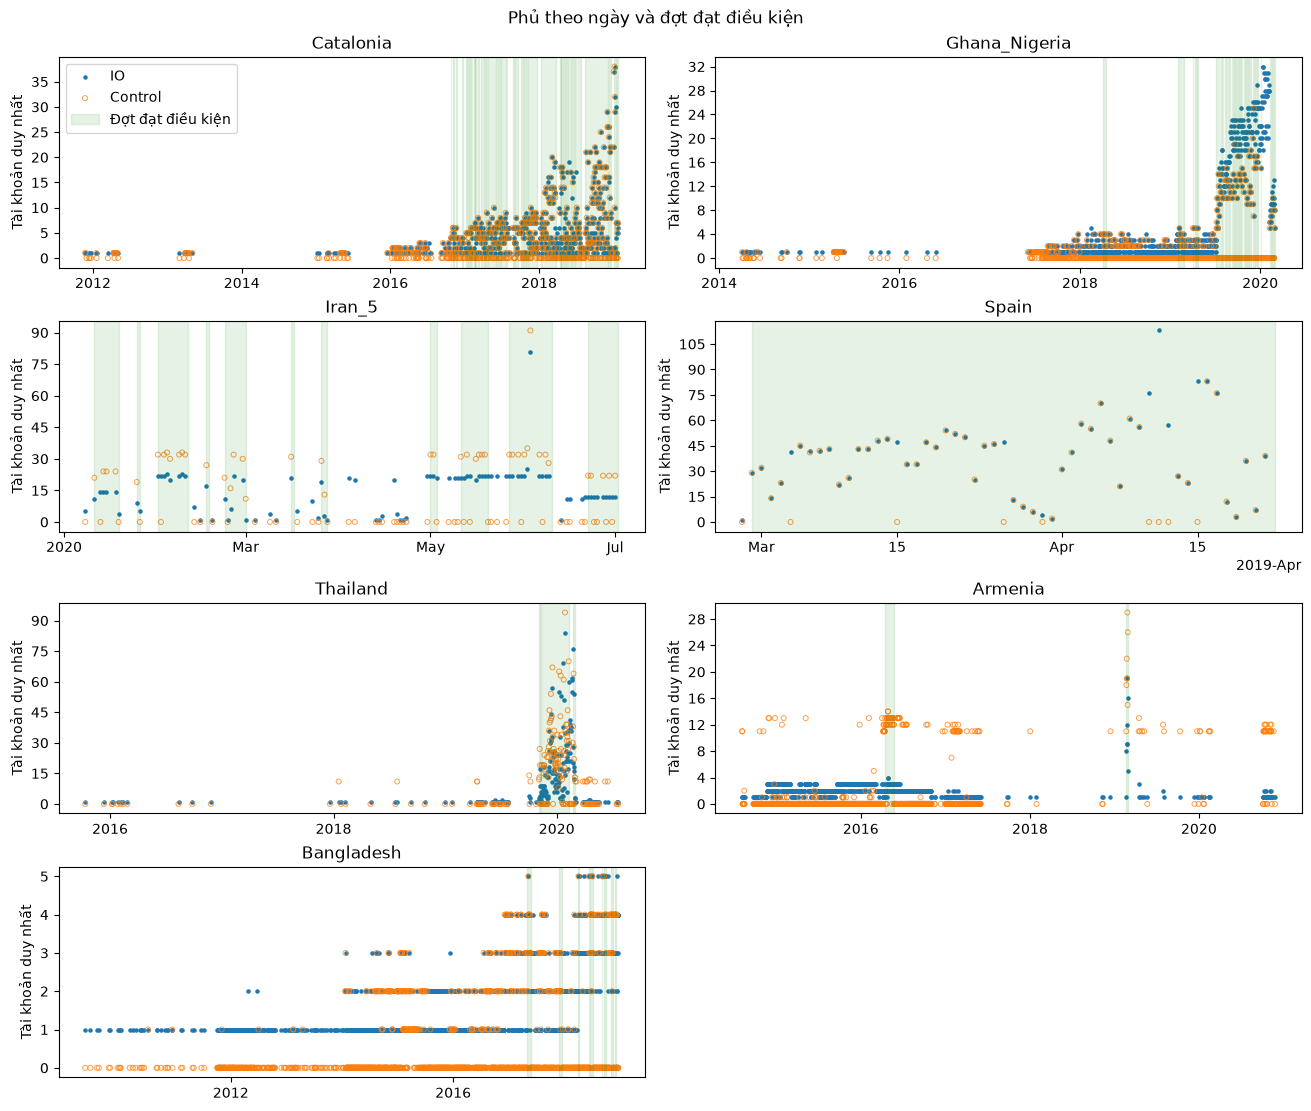

Tập chính: 3/7 chiến dịch.


In [5]:
streams, episode_tables, selection_rows, episode_reports = {}, {}, [], []
for campaign, frame in frames.items():
    daily = daily_tables[campaign]
    for c in RULES.control_minima:
        stream, episodes = make_episodes(frame, daily, RULES, c)
        assert stream.day.isin(daily.index[daily[f"covered_c{c}"]]).all()
        assert len(stream) == daily.loc[daily[f"covered_c{c}"], ["io_actions", "ctrl_actions"]].sum().sum()
        selection_rows.append(dict(campaign=campaign, **select_campaign(daily, episodes, RULES, c)))
        episode_reports.append(episodes.reset_index().assign(campaign=campaign, control_min=c))
        if c == MAIN_C:
            streams[campaign], episode_tables[campaign] = stream, episodes
del frames

selection_all = pd.DataFrame(selection_rows)
selection_all["main_threshold"] = selection_all.control_min.eq(MAIN_C)
selection_all["set"] = np.where(selection_all.in_main_set, "main", "appendix")
selection = selection_all.loc[selection_all.main_threshold]
main_campaigns = set(selection.loc[selection.in_main_set, "campaign"])
export("p3_episodes", pd.concat(episode_reports, ignore_index=True))
export("p3_campaign_selection", selection_all, preview=7)

fig, axes = plt.subplots(4, 2, figsize=(13, 11), layout="constrained")
for campaign, ax in zip(CAMPAIGNS, axes.flat):
    daily = daily_tables[campaign]
    ax.scatter(daily.index, daily.io_accounts, s=5, label="IO")
    ax.scatter(daily.index, daily.ctrl_accounts, s=13, facecolors="none", edgecolors="tab:orange",
               linewidths=.7, alpha=.75, label="Control")
    for episode in episode_tables[campaign].itertuples():
        if episode.qualified:
            ax.axvspan(episode.start, episode.end + pd.Timedelta(days=1), alpha=.1, color="green")
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set(title=campaign, ylabel="Tài khoản duy nhất")
axes.flat[-1].axis("off")
qualified_patch = Patch(color="green", alpha=.1, label="Đợt đạt điều kiện")
axes.flat[0].legend(handles=[*axes.flat[0].collections, qualified_patch], loc="upper left")
fig.suptitle("Phủ theo ngày và đợt đạt điều kiện")
save_figure(fig, "p3_daily_coverage.png")
print(f"Tập chính: {len(main_campaigns)}/{len(CAMPAIGNS)} chiến dịch.")

**Nhận xét.** Vùng tô là khoảng lịch của đợt; luồng chỉ lấy các ngày được phủ. Khóa lựa chọn ở ngưỡng chính trước khi xem điểm mô hình.

## P4 — Mốc

Trong mỗi đợt đạt, mốc q ∈ {10, 25, 50, 100}% lấy timestamp IO ở vị trí `ceil(q·N) − 1`; mốc ngày {1, 3, 7} chốt 23:59 UTC của ngày thứ d nếu đợt đủ dài. Mốc chỉ được đánh giá khi đến τ có ≥ 5 IO và ≥ 5 control trong đợt; mốc không đạt vẫn được giữ với `eligible=False`. Tập đánh giá tại τ là tài khoản hoạt động trong đợt đến τ.

,campaign,checkpoints,eligible,ineligible
0,Catalonia,229,174,55
1,Ghana_Nigeria,160,115,45
2,Iran_5,67,61,6
3,Spain,7,7,0
4,Thailand,20,18,2
5,Armenia,14,10,4
6,Bangladesh,58,22,36


Có 148 mốc không đủ điều kiện.


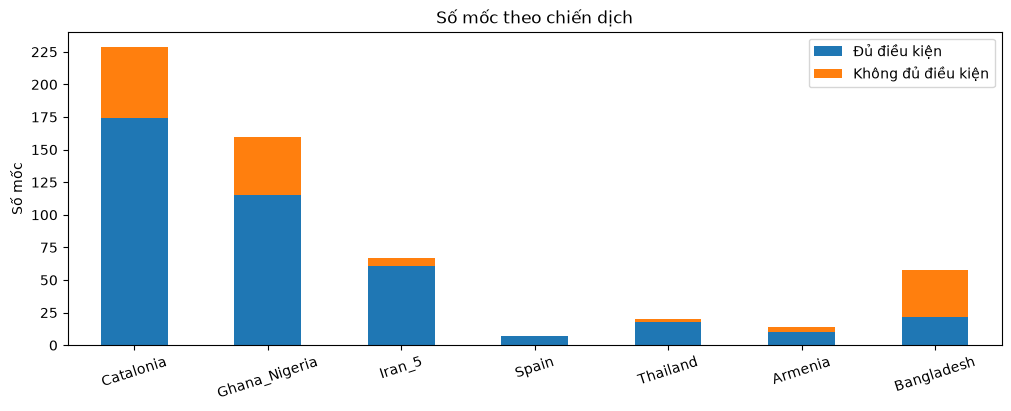

In [6]:
checkpoints = {
    campaign: make_checkpoints(streams[campaign], episode_tables[campaign], RULES).assign(campaign=campaign)
    for campaign in CAMPAIGNS
}
marks = pd.concat(checkpoints.values(), ignore_index=True)
counts = marks.groupby("campaign").eligible.agg(checkpoints="size", eligible="sum")
counts = counts.reindex(CAMPAIGNS, fill_value=0).rename_axis("campaign").reset_index()
counts["ineligible"] = counts["checkpoints"] - counts["eligible"]
export("p4_checkpoints", marks)
export("p4_checkpoint_counts", counts, preview=7)
print(f"Có {int(counts.ineligible.sum())} mốc không đủ điều kiện.")

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
counts.set_index("campaign")[["eligible", "ineligible"]].rename(
    columns={"eligible": "Đủ điều kiện", "ineligible": "Không đủ điều kiện"}).plot.bar(ax=ax, stacked=True, rot=18)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set(title="Số mốc theo chiến dịch", ylabel="Số mốc", xlabel="")
save_figure(fig, "p4_checkpoint_counts.png")

## P4b và P5 — Baseline tầm thường

Tại mỗi mốc đạt, tính ba điểm cho cùng tập đánh giá: (i) thứ hạng thời điểm xuất hiện đầu tiên trong đợt, (ii) số hành động chia số ngày hoạt động trong đợt đến τ, (iii) tỷ lệ cặp repost T10 có Δt = 0 mà tài khoản là nguồn, trên prefix của đợt (`keep_zero=True`; không có cặp nhận 0). Mỗi điểm báo cáo ROC-AUC và oracle top-k F1* cho cả hai chiều. Nhãn chỉ dùng để chấm.

P4b: với từng chiến dịch và từng mức mốc, lấy trung bình các đợt với trọng số đều và trọng số theo số hành động IO; CI 95% bootstrap theo đợt trong chiến dịch. Kiểm định giữa phương pháp ở cấp chiến dịch được làm khi có B1 từ T7, dùng `compare_campaigns` trên các chiến dịch thuộc tập chính.

In [7]:
def summarize_scores(scores, metrics):
    tables = [aggregate_episodes(scores, metric, BOOTSTRAP_SEED, BOOTSTRAP_REPS) for metric in metrics]
    return pd.concat(tables, ignore_index=True).merge(selection[["campaign", "set"]], on="campaign",
                                                     validate="many_to_one")


baselines = pd.concat([evaluate_baselines(streams[c], checkpoints[c]) for c in CAMPAIGNS], ignore_index=True)
export("p5_baselines", baselines)
oracle = baselines.drop_duplicates([*CHECKPOINT_KEYS, "method"])
export("p4b_p5_summary", summarize_scores(oracle, ["F1_star_best_direction"]))

if len(baselines):
    display(baselines.groupby(["method", "direction"]).agg(
        checkpoint_rows=("F1_star", "size"), median_auc=("auc", "median"), median_f1=("F1_star", "median")))
else:
    print("Không có mốc đủ điều kiện để chấm P5.")

checkpoint_rows  median_auc  median_f1
method                 direction                                        
actions_per_active_day high                   407    0.121795   0.558140
                       low                    407    0.878205   0.823529
first_seen             high                   407    0.428571   0.632653
                       low                    407    0.571429   0.666667
zero_delta_repost      high                   407    0.500000   0.666667
                       low                    407    0.500000   0.588235

**Nhận xét.** AUC thấp theo một chiều có thể đi cùng AUC cao ở chiều ngược lại, nên đọc cả hai chiều. Ước lượng chính nằm trong `p4b_p5_summary.csv` (đơn vị: đợt trong chiến dịch); trung vị ở bảng trên chỉ để xem nhanh.

## P6 — Ablation và kiểm tra định tính

Tại mỗi mốc đạt và mỗi seed, so cấu hình chính (đủ bốn lớp) với: bỏ lớp hashtag; S1 xáo trộn `t_min` trong cùng tài khoản–ngày (giữ khối lượng ngày và nội dung, đổi liên kết thời gian); giữ K hành động đầu tiên/tài khoản/ngày với K chốt ở P2; reset trạng thái trên Catalonia. `p6_deltas_vs_main.csv` báo thay đổi F1*, WP so với cấu hình chính: trung bình đều theo đợt trong từng seed, rồi trung bình và SD giữa các seed. Kiểm tra định tính: 10 cụm có nhiều control nhất ở mốc muộn nhất của mỗi chiến dịch (cấu hình chính, seed đầu), chỉ ghi số đếm tổng hợp; không có ID tài khoản, nội dung hay trích nguyên văn bài đăng. Chỉ chạy khi khóa `t9_adapter` trong `configs/t7.json` có dạng `module:function`; hàm `infer_partition(events, nodes, layers, seed)` không nhận nhãn và trả phân hoạch phủ đúng danh sách nút.

In [8]:
p6_status = "P6 chưa chạy xong" if ADAPTER else "Chưa khai báo adapter T7"
if ADAPTER:
    module_name, function_name = ADAPTER.split(":", 1)
    infer_partition = getattr(import_module(module_name), function_name)
    runs = [evaluate_ablations(streams[c], checkpoints[c], infer_partition, SEEDS, CAP_K[c], reset_state=c == RESET_CAMPAIGN) for c in CAMPAIGNS]
    p6 = pd.concat([scores for scores, _ in runs], ignore_index=True)
    p6_summary = ablation_summary(ablation_deltas(p6)).merge(selection[["campaign", "set"]], on="campaign", validate="many_to_one")
    clusters = pd.concat([control for _, control in runs], ignore_index=True)
    export("p6_scores", p6)
    export("p6_deltas_vs_main", p6_summary)
    export("p6_control_clusters", clusters)
    quick = p6_summary.loc[p6_summary.checkpoint_type.eq("io_pct")]
    display(quick.pivot_table(index=["campaign", "checkpoint_value"], columns="method", values=["delta_F1_star_mean", "delta_WP_mean"]).round(3))
    display(clusters.groupby("campaign").agg(clusters=("rank", "size"), median_accounts=("accounts", "median"), median_control_share=("control_share", "median"), repeated_sync_share=("repeated_sync", "mean"), **{f"clusters_shared_{x}": (f"shared_{x}", lambda v: int(v.gt(0).sum())) for x in LAYERS}))
    p6_status = f"Đã chạy adapter, {len(p6)} dòng điểm"
print(p6_status)

KeyboardInterrupt: 

## Kết thúc

`run.json` ghi cấu hình, git hash, thời gian chạy và danh sách tệp. Dòng in cuối là câu trả lời số cho câu hỏi 4 của review 04 (số chiến dịch tập chính, số mốc không đủ điều kiện).

In [9]:
git = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, capture_output=True, text=True, check=False)
dirty = subprocess.run(["git", "status", "--porcelain", "--", "src", "notebooks/T9_EDA_Seckin.ipynb"],
                       cwd=ROOT, capture_output=True, text=True, check=False)
metadata = dict(
    status="completed", git_head=git.stdout.strip() or None, code_dirty=bool(dirty.stdout.strip()),
    finished_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
    runtime_seconds=round(perf_counter() - started, 1), protocol="Review 03 §6.2",
    rules=asdict(RULES), seeds=SEEDS, bootstrap_seed=BOOTSTRAP_SEED, bootstrap_reps=BOOTSTRAP_REPS, cap_k=CAP_K, cap_k_rule=f"ceil(median IO actions/account/day, covered_c{MAIN_C})",
    reset_campaign=RESET_CAMPAIGN, adapter=ADAPTER or None, p6_status=p6_status,
    main_set_campaigns=sorted(main_campaigns), ineligible_checkpoints=int(counts.ineligible.sum()),
    outputs=written,
)
(out_dir / "run.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"Tập chính {len(main_campaigns)}/{len(CAMPAIGNS)}: {', '.join(sorted(main_campaigns)) or 'không có'}.")
print(f"Mốc không đủ điều kiện: {metadata['ineligible_checkpoints']}/{len(marks)}.")
print(f"Kết quả tại {out_dir.relative_to(ROOT)}.")

Tập chính 3/7: Catalonia, Iran_5, Thailand.
Mốc không đủ điều kiện: 148/555.
Kết quả tại reports\T9_EDA_Seckin.
